# Binary QML Pipeline — LYA vs LYT
## ResNet34 (MLL23) → PCA → quantum *vs* classical kernels

**Central question.** Does a **quantum kernel** provide a *measurable* advantage over classical kernels (RBF, polynomial, linear) trained **on the exact same ResNet+PCA features**?

This notebook isolates a difficult binary problem from the MicroscopyRGB task (Matek Ma190c) — **LYA** (atypical lymphocytes, n ≈ 30) versus **LYT** (typical lymphocytes, n ≈ 224) — two visually and biologically close classes, on a dataset small enough for kernel methods.

The pipeline:

1. **Pre-trained ResNet34 on MLL23** as a *frozen* feature extractor.
2. Extraction of deep visual embeddings (512-d) for each image.
3. Dimensionality reduction **fitted only on the train set** (`StandardScaler + PCA` → `n_qubits` dimensions).
4. Encoding of the reduced vector into a **quantum feature map**.
5. Computation of a **quantum kernel matrix** + kernel SVM (`kernel="precomputed"`).

> The ResNet acts as a strong classical visual encoder; the PCA provides a **controlled bottleneck** towards the quantum kernel. The quantum kernel therefore does *not* learn low-level features from pixels: it operates on a compact, domain-informed representation.

---

### Experimental discipline (non-negotiable)

- **No leakage.** `StandardScaler`, `PCA`, and angle scaling are **fitted on the train set only**, then applied to the test set. This is critical here: LYA has only about thirty examples, the slightest leak artificially inflates the scores.
- **Imbalance prohibits *accuracy*.** We report: *balanced accuracy*, *macro-F1*, **LYA recall**, **LYA precision**, **PR-AUC**, confusion matrix, and confidence intervals over repeated splits.
- **Paired comparison.** Classical and quantum are evaluated on **the same folds** (same `random_state`). The relevant metric is the delta per split; a difference is only claimed if its 95% CI excludes 0.
- **Over-expressivity = danger.** Kernel matrices are inspected directly (rank, conditioning, kernel-target alignment, proximity to identity). A kernel that perfectly separates the train set but generalizes poorly signals a feature map that is too expressive for the dataset size.

## 0 · Installation (run once if needed)

In [1]:
# !pip install pennylane scikit-learn torch torchvision tifffile matplotlib seaborn
# PennyLane provides AngleEmbedding / IQPEmbedding and qml.kernels.target_alignment.
# torch+torchvision are used only for ResNet34 extraction (frozen backbone).

## 1 · Imports, seeds and configuration

In [2]:
import os, time, json, warnings, pickle
from pathlib import Path
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedShuffleSplit, StratifiedKFold
from sklearn.metrics import (balanced_accuracy_score, f1_score, recall_score,
                             precision_score, average_precision_score,
                             confusion_matrix, classification_report)
from sklearn.metrics.pairwise import linear_kernel, rbf_kernel, polynomial_kernel

import pennylane as qml

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
print("PennyLane", qml.__version__, "| NumPy", np.__version__)

PennyLane 0.45.1 | NumPy 2.4.6


In [3]:
class CFG:
    # ── Data (adapt to local paths) ──────────────────────────────────
    RGB_DIR    = "/Users/poupou/Desktop/Pipeline SQDO/dataset"
    LABEL_FILE = "/Users/poupou/Desktop/Pipeline SQDO/data/Ma190c_annotations.dat"
    IMG_EXTENSIONS = [".tif", ".tiff", ".TIF", ".TIFF"]
    POS_CLASS  = "LYA"        # minority class of interest (positive label)
    NEG_CLASS  = "LYT"        # majority class

    # ── Pretrained ResNet34 backbone on MLL23 ──────────────────────────────────
    # Path to a ResNet34 state_dict trained on MLL23 (18 classes).
    # If absent, EXPLICIT fallback to ImageNet (see warning in §3).
    MLL23_CKPT  = "/Users/poupou/Desktop/Pipeline SQDO/resnet34_mll23_backbone/resnet34_mll23_backbone.pth"
    IMG_SIZE    = 224
    BATCH       = 16

    # ── Reduction & kernels ────────────────────────────────────────────────────
    PCA_DIMS    = [2, 4, 6, 8, 10, 12]   # = n_qubits for the feature maps
    FEATURE_MAPS = ["angle", "zz", "iqp", "reupload"]
    REPS        = 2                       # repetitions (IQP / data re-uploading)
    C_GRID      = [0.1, 1.0, 4.0, 16.0, 64.0]

    # ── Evaluation ────────────────────────────────────────────────────────────
    N_SPLITS    = 15                      # repeated stratified splits
    TEST_SIZE   = 0.25
    IMBALANCE   = "balanced"              # "balanced" | "undersample"
    INNER_CV    = 3                       # folds for C selection

    # ── I/O ───────────────────────────────────────────────────────────────────
    OUTPUT_DIR  = "./outputs_lya_lyt"
    EMB_CACHE   = "resnet34_mll23_lya_lyt_embeddings.npz"
    RES_CACHE   = "qk_vs_classical_results.pkl"

os.makedirs(CFG.OUTPUT_DIR, exist_ok=True)
print("Classes:", CFG.POS_CLASS, "(positive) vs", CFG.NEG_CLASS)
print("PCA/qubits:", CFG.PCA_DIMS, "| feature maps:", CFG.FEATURE_MAPS)
print("Splits:", CFG.N_SPLITS, "| imbalance strategy:", CFG.IMBALANCE)

Classes: LYA (positive) vs LYT
PCA/qubits: [2, 4, 6, 8, 10, 12] | feature maps: ['angle', 'zz', 'iqp', 'reupload']
Splits: 15 | imbalance strategy: balanced


## 2 · Loading LYA / LYT images

We read the Ma190c annotations, filter the two classes of interest, then load the RGB `.tif` images.
The expected imbalance (~30 LYA / ~224 LYT) is displayed as-is: it drives the entire evaluation protocol.

In [4]:
import tifffile

def load_labels(label_file):
    rows = []
    with open(label_file) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 2:
                rows.append({"name": parts[0], "label": parts[1]})
    return pd.DataFrame(rows)

def find_image(rgb_dir, name, exts):
    for ext in exts:
        p = Path(rgb_dir) / (name + ext)
        if p.exists():
            return str(p)
    return None

def load_binary_dataset(cfg):
    df = load_labels(cfg.LABEL_FILE)
    df = df[df["label"].isin([cfg.POS_CLASS, cfg.NEG_CLASS])].reset_index(drop=True)
    images, labels, names, missing = [], [], [], 0
    for _, row in df.iterrows():
        path = find_image(cfg.RGB_DIR, row["name"], cfg.IMG_EXTENSIONS)
        if path is None:
            missing += 1; continue
        img = tifffile.imread(path)
        if img.dtype != np.uint8:
            img = (img / (img.max() + 1e-9) * 255).astype(np.uint8)
        if img.ndim == 2:
            img = np.stack([img] * 3, axis=-1)
        if img.shape[-1] > 3:
            img = img[..., :3]
        images.append(img); labels.append(row["label"]); names.append(row["name"])
    labels = np.array(labels)
    print(f"{len(images)} images loaded | missing: {missing}")
    print("Distribution:", dict(Counter(labels)))
    return images, labels, names

# Uncomment when the CFG paths are correct:
images, labels_str, names = load_binary_dataset(CFG)
y = (labels_str == CFG.POS_CLASS).astype(int)   # 1 = LYA (positive)

254 images loaded | missing: 6
Distribution: {np.str_('LYT'): 224, np.str_('LYA'): 30}


## 3 · Pretrained ResNet34 backbone on MLL23 (frozen)

**Important & honest note.** MLL23 is a *dataset* (Munich Leukemia Laboratory / marrlab, 41,906 images, 18 classes). The "ResNet34 pretrained on MLL23" is a **checkpoint that you provide** via `CFG.MLL23_CKPT` (a ResNet34 `state_dict` trained on the 18 MLL23 classes).

The function below:

- loads the torchvision `resnet34` architecture;
- if the MLL23 checkpoint exists → loads its weights (the 18-class `fc` head is ignored, only the encoder up to `avgpool` is kept);
- **otherwise → explicit fallback to ImageNet** with a visible warning. In that fallback case, the claim of a "representation informed by the hematological domain" **no longer holds**: the results remain valid as a quantum/classical comparison, but the "MLL23" semantics are lost. This should be flagged in any report.

The backbone is **frozen** (`eval()`, `requires_grad=False`): no fine-tuning, pure extraction.

In [5]:
import torch
import torch.nn as nn
import torchvision.transforms as T
from torchvision.models import resnet34, ResNet34_Weights

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def build_backbone(cfg):
    ckpt = Path(cfg.MLL23_CKPT)
    if ckpt.exists():
        model = resnet34(weights=None)
        state = torch.load(ckpt, map_location="cpu")
        state = state.get("state_dict", state)          # handles Lightning/ensemble checkpoints
        state = {k.replace("module.", "").replace("model.", ""): v for k, v in state.items()}
        # only load what matches the encoder (the 18-class fc head differs)
        enc = {k: v for k, v in state.items() if k in model.state_dict()
               and v.shape == model.state_dict()[k].shape}
        missing = model.load_state_dict(enc, strict=False)
        source = f"MLL23 ({len(enc)} tensors loaded from {ckpt.name})"
    else:
        print("⚠️  WARNING: MLL23 checkpoint not found at", cfg.MLL23_CKPT)
        print("   → falling back to ResNet34/ImageNet. The 'hematological domain' semantics is LOST.")
        print("   → this must be explicitly mentioned in any FNS report / preprint.")
        model = resnet34(weights=ResNet34_Weights.IMAGENET1K_V1)
        source = "ImageNet (FALLBACK — not MLL23)"

    model.fc = nn.Identity()                 # output = 512-d embedding (post-avgpool)
    model.eval().to(DEVICE)
    for p in model.parameters():
        p.requires_grad = False
    print("Backbone:", source, "| device:", DEVICE)
    return model, source

# Standard ImageNet normalization (MLL23 preprocessing should be close to this;
# if your MLL23 checkpoint uses different stats, replace mean/std below).
PREPROCESS = T.Compose([
    T.ToTensor(),
    T.Resize((CFG.IMG_SIZE, CFG.IMG_SIZE), antialias=True),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

## 4 · Embedding extraction (512-d) + cache

Embeddings are extracted once then cached (`.npz`). No label data is involved here: extraction is fully independent of the splits, so there is no leakage.

In [6]:
@torch.no_grad()
def extract_embeddings(model, images, batch=16):
    feats = []
    for i in range(0, len(images), batch):
        batch_imgs = images[i:i + batch]
        x = torch.stack([PREPROCESS(im) for im in batch_imgs]).to(DEVICE)
        f = model(x)                          # (B, 512)
        feats.append(f.cpu().numpy())
    return np.concatenate(feats, axis=0)

def get_embeddings(cfg, images=None, y=None, names=None):
    cache = Path(cfg.OUTPUT_DIR) / cfg.EMB_CACHE
    if cache.exists():
        d = np.load(cache, allow_pickle=True)
        print("Embeddings loaded from cache:", d["X"].shape)
        return d["X"], d["y"], d["names"], str(d["backbone"])
    model, source = build_backbone(cfg)
    X = extract_embeddings(model, images, cfg.BATCH)
    np.savez(cache, X=X, y=y, names=np.array(names), backbone=source)
    print("Embeddings extracted & cached:", X.shape, "| backbone:", source)
    return X, y, np.array(names), source

# Uncomment after loading the images (§2):
X, y, names, backbone_source = get_embeddings(CFG, images, y, names)
print("X:", X.shape, "| y:", dict(Counter(y.tolist())))

Embeddings loaded from cache: (254, 512)
X: (254, 512) | y: {0: 224, 1: 30}


## 5 · Quantum feature maps → fidelity kernel

We simulate **exact statevectors** (`default.qubit`) and form the **fidelity kernel**
$K_{ij} = |\langle \phi(x_i)\,|\,\phi(x_j)\rangle|^2$ — equivalent to the quantum state-overlap kernel.

Four feature maps spanning the expressivity spectrum:

| Name | Encoding | Intuition |
|---|---|---|
| `angle` | $R_Y(x_i)$ per qubit | product encoding, low expressivity, robust |
| `zz` | H + $R_Z(x_i)$ + $R_{ZZ}$ on a ring | pairwise correlations (ZZFeatureMap style) |
| `iqp` | `IQPEmbedding` (repeated) | IQP interference, more expressive |
| `reupload` | interleaved $R_Y/R_Z$ re-encoding | *data re-uploading*, most expressive |

`n_qubits = pca_dim`: the PCA sweep **is** the sweep over the number of qubits.

In [7]:
def make_statevector_fn(n_qubits, kind="angle", reps=2):
    dev = qml.device("default.qubit", wires=n_qubits)

    def angle(x):
        qml.AngleEmbedding(x, wires=range(n_qubits), rotation="Y")

    def zz(x):
        for i in range(n_qubits):
            qml.Hadamard(wires=i)
            qml.RZ(x[i], wires=i)
        for i in range(n_qubits):
            j = (i + 1) % n_qubits
            qml.CNOT(wires=[i, j])
            qml.RZ((np.pi - x[i]) * (np.pi - x[j]), wires=j)
            qml.CNOT(wires=[i, j])

    def iqp(x):
        qml.IQPEmbedding(x, wires=range(n_qubits), n_repeats=reps)

    def reupload(x):
        for _ in range(reps):
            qml.AngleEmbedding(x, wires=range(n_qubits), rotation="Y")
            for i in range(n_qubits):
                qml.CNOT(wires=[i, (i + 1) % n_qubits])
            qml.AngleEmbedding(x, wires=range(n_qubits), rotation="Z")

    fmap = {"angle": angle, "zz": zz, "iqp": iqp, "reupload": reupload}[kind]

    @qml.qnode(dev)
    def circuit(x):
        fmap(x)
        return qml.state()

    def statevectors(X):
        return np.stack([circuit(np.asarray(x, dtype=float)) for x in X])
    return statevectors

def fidelity_kernel(sv_a, sv_b):
    """K_ij = |<a_i|b_j>|^2."""
    overlap = np.conjugate(sv_a) @ sv_b.T
    return np.abs(overlap) ** 2

## 6 · Kernel diagnostics (before classification)

To detect kernel overfitting and compare the quantum/classical *geometries* **before** any classification:

- **Rank** and **condition number** of the train Gram matrix (low rank ⇒ limited information; huge condition number ⇒ near-singular).
- **Proximity to identity**: mean of the off-diagonal terms. Close to 0 ⇒ the kernel tends toward identity (kernel concentration, each point orthogonal to the others) ⇒ poor generalization expected.
- **Centered kernel-target alignment (KTA)**: $\hat{A} = \dfrac{\langle K_c, yy^\top\rangle}{\|K_c\|_F\,\|yy^\top\|_F}$ with $K_c = HKH$ (centering). Measures how much the kernel geometry aligns with the labels, **independently of the classifier**.

A quantum KTA higher than that of RBF/poly would support the idea that the feature map captures a useful geometry. Otherwise, any performance gap is probably split noise.

In [8]:
def signed_labels(y):
    classes = np.unique(y)
    return np.where(np.asarray(y) == classes[-1], 1.0, -1.0)

def centered_kta(K, y):
    """Centered kernel-target alignment, binary y."""
    yv = signed_labels(y)
    T = np.outer(yv, yv)
    n = K.shape[0]
    H = np.eye(n) - np.ones((n, n)) / n
    Kc = H @ K @ H
    return float(np.sum(Kc * T) / (np.linalg.norm(Kc) * np.linalg.norm(T) + 1e-12))

def kernel_diagnostics(K, y):
    n = K.shape[0]
    eig = np.linalg.eigvalsh((K + K.T) / 2)
    eig = np.clip(eig, 0, None)
    pos = eig[eig > 1e-12]
    return dict(
        rank=int(np.sum(eig > 1e-10)),
        cond=float(eig.max() / pos.min()) if len(pos) else np.inf,
        mean_offdiag=float(K[~np.eye(n, dtype=bool)].mean()),
        identity_gap=float(1.0 - K[~np.eye(n, dtype=bool)].mean()),  # →1 if K≈Identity
        kta=centered_kta(K, y),
    )

def classical_gram(Z_a, Z_b, kind, gamma="scale", degree=3, coef0=1.0):
    if kind == "linear":
        return linear_kernel(Z_a, Z_b)
    if kind == "rbf":
        g = 1.0 / (Z_a.shape[1] * Z_a.var()) if gamma == "scale" else gamma
        return rbf_kernel(Z_a, Z_b, gamma=g)
    if kind == "poly":
        g = 1.0 / (Z_a.shape[1] * Z_a.var()) if gamma == "scale" else gamma
        return polynomial_kernel(Z_a, Z_b, degree=degree, gamma=g, coef0=coef0)
    raise ValueError(kind)

## 7 · Leakage-free evaluation harness (repeated stratified splits)

For **each** stratified split:

1. `StandardScaler` **fit on train**, applied to test.
2. `PCA(n_components = n_qubits)` **fit on train**, applied to test.
3. Angle scaling to $[-\pi, \pi]$ via a `MinMaxScaler` **fit on train** (essential for the encoding — otherwise the rotations wrap arbitrarily).
4. Kernel (quantum *or* classical) computed, `precomputed` SVM, **C selected by inner CV** on the train set.
5. Metrics on the test set + kernel diagnostics on the train set.

The same split indices are used for the classical baselines and the quantum kernels ⇒ **paired comparison**.

**Imbalance.** Two switchable strategies: `class_weight="balanced"` (default) or controlled undersampling of the majority class (LYT) on the train set only.

In [9]:
def make_splits(y, n_splits, test_size, seed=SEED):
    sss = StratifiedShuffleSplit(n_splits=n_splits, test_size=test_size, random_state=seed)
    return list(sss.split(np.zeros(len(y)), y))

def maybe_undersample(idx_tr, y, strategy, seed):
    if strategy != "undersample":
        return idx_tr
    rng = np.random.default_rng(seed)
    ytr = y[idx_tr]
    pos = idx_tr[ytr == 1]; neg = idx_tr[ytr == 0]
    k = min(len(neg), 3 * len(pos))                 # controlled ~3:1 ratio
    neg_ds = rng.choice(neg, size=k, replace=False)
    out = np.concatenate([pos, neg_ds]); rng.shuffle(out)
    return out

def prep_train_only(X, idx_tr, idx_te, pca_dim, angle_scaled=True):
    """Scaler+PCA(+MinMax angles) fitted ON TRAIN ONLY."""
    sc  = StandardScaler().fit(X[idx_tr])
    pca = PCA(n_components=pca_dim, random_state=0).fit(sc.transform(X[idx_tr]))
    Ztr = pca.transform(sc.transform(X[idx_tr]))
    Zte = pca.transform(sc.transform(X[idx_te]))
    if angle_scaled:
        mm = MinMaxScaler((-np.pi, np.pi)).fit(Ztr)
        return mm.transform(Ztr), mm.transform(Zte), Ztr, Zte
    return Ztr, Zte, Ztr, Zte

def select_C_precomputed(Ktr, ytr, Cs, class_weight, n_splits=3, seed=SEED):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    best_C, best = Cs[0], -1.0
    for C in Cs:
        sc = []
        for a, b in skf.split(np.zeros(len(ytr)), ytr):
            clf = SVC(kernel="precomputed", class_weight=class_weight, C=C)
            clf.fit(Ktr[np.ix_(a, a)], ytr[a])
            p = clf.predict(Ktr[np.ix_(b, a)])
            sc.append(f1_score(ytr[b], p, average="macro"))
        m = float(np.mean(sc))
        if m > best:
            best, best_C = m, C
    return best_C

def metrics_from(yte, pred, score):
    return dict(
        bacc     = balanced_accuracy_score(yte, pred),
        f1_macro = f1_score(yte, pred, average="macro"),
        lya_rec  = recall_score(yte, pred, pos_label=1, zero_division=0),
        lya_prec = precision_score(yte, pred, pos_label=1, zero_division=0),
        pr_auc   = average_precision_score(yte, score),
    )

In [10]:
def run_kernel_experiment(X, y, splits, kernel_spec, pca_dim, cfg):
    """kernel_spec = {'family':'quantum','map':'zz'} or {'family':'classical','kind':'rbf'}."""
    cw = "balanced" if cfg.IMBALANCE == "balanced" else None
    per_split = []
    svfn = None
    if kernel_spec["family"] == "quantum":
        svfn = make_statevector_fn(pca_dim, kernel_spec["map"], cfg.REPS)
    for s, (idx_tr, idx_te) in enumerate(splits):
        idx_tr2 = maybe_undersample(idx_tr, y, cfg.IMBALANCE, seed=SEED + s)
        Ztr, Zte, Ztr_raw, Zte_raw = prep_train_only(
            X, idx_tr2, idx_te, pca_dim,
            angle_scaled=(kernel_spec["family"] == "quantum"))
        ytr, yte = y[idx_tr2], y[idx_te]

        if kernel_spec["family"] == "quantum":
            svtr, svte = svfn(Ztr), svfn(Zte)
            Ktr = fidelity_kernel(svtr, svtr)
            Kte = fidelity_kernel(svte, svtr)
        else:
            Ktr = classical_gram(Ztr_raw, Ztr_raw, kernel_spec["kind"])
            Kte = classical_gram(Zte_raw, Ztr_raw, kernel_spec["kind"])

        C = select_C_precomputed(Ktr, ytr, cfg.C_GRID, cw, cfg.INNER_CV, seed=SEED + s)
        clf = SVC(kernel="precomputed", class_weight=cw, C=C).fit(Ktr, ytr)
        pred  = clf.predict(Kte)
        score = clf.decision_function(Kte)

        row = metrics_from(yte, pred, score)
        row.update(kernel_diagnostics(Ktr, ytr))
        row["C"] = C; row["split"] = s
        per_split.append(row)
    return per_split

### Aggregation: mean + 95% CI (bootstrap over splits) and paired comparison

In [11]:
METRIC_KEYS = ["bacc", "f1_macro", "lya_rec", "lya_prec", "pr_auc",
               "kta", "rank", "cond", "identity_gap"]

def summarize(per_split, keys=METRIC_KEYS, n_boot=5000, seed=SEED):
    rng = np.random.default_rng(seed)
    out = {}
    for k in keys:
        v = np.array([r[k] for r in per_split], dtype=float)
        boot = [rng.choice(v, size=len(v), replace=True).mean() for _ in range(n_boot)]
        out[k] = dict(mean=float(v.mean()),
                      lo=float(np.percentile(boot, 2.5)),
                      hi=float(np.percentile(boot, 97.5)))
    return out

def paired_delta(q_rows, c_rows, key, n_boot=5000, seed=SEED):
    """Paired delta quantum - classical (same splits). Significant if CI excludes 0."""
    rng = np.random.default_rng(seed)
    d = np.array([q[key] for q in q_rows]) - np.array([c[key] for c in c_rows])
    boot = [rng.choice(d, size=len(d), replace=True).mean() for _ in range(n_boot)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return dict(mean=float(d.mean()), lo=float(lo), hi=float(hi),
                significant=bool(lo > 0 or hi < 0))

def fmt(ci): return f"{ci['mean']:.3f} [{ci['lo']:.3f}, {ci['hi']:.3f}]"

## 8 · Orchestration: classical baselines + quantum kernels (same folds)

We freeze the list of splits **once** and reuse it everywhere ⇒ all comparisons are paired.
The full sweep (PCA_DIMS × feature maps × baselines × splits) is cached (`.pkl`).

In [12]:
def run_full_sweep(X, y, cfg, force=False):
    cache = Path(cfg.OUTPUT_DIR) / cfg.RES_CACHE
    if cache.exists() and not force:
        print("Results loaded from cache:", cache.name)
        return pickle.load(open(cache, "rb"))

    splits = make_splits(y, cfg.N_SPLITS, cfg.TEST_SIZE, seed=SEED)
    classical_kinds = ["linear", "rbf", "poly"]
    results = {"pca_dims": cfg.PCA_DIMS, "classical": {}, "quantum": {},
               "imbalance": cfg.IMBALANCE, "n_splits": cfg.N_SPLITS}

    t0 = time.time()
    for d in cfg.PCA_DIMS:
        for kind in classical_kinds:
            results["classical"][(kind, d)] = run_kernel_experiment(
                X, y, splits, {"family": "classical", "kind": kind}, d, cfg)
        for fmap in cfg.FEATURE_MAPS:
            results["quantum"][(fmap, d)] = run_kernel_experiment(
                X, y, splits, {"family": "quantum", "map": fmap}, d, cfg)
        print(f"  PCA={d:2d} qubits ✓  ({time.time()-t0:.0f}s)")

    pickle.dump(results, open(cache, "wb"))
    print("Sweep finished & cached.")
    return results

# Uncomment once X, y are available:
results = run_full_sweep(X, y, CFG)

Results loaded from cache: qk_vs_classical_results.pkl


## 9 · Classical baselines (reference)

The **RBF SVM** is the most important baseline: it is a strong nonlinear kernel method, trained on *exactly* the same features. Beating RBF (non-overlapping CI) is the bar to clear to claim a quantum advantage.

In [13]:
def classical_table(results, dim):
    rows = []
    for kind in ["linear", "rbf", "poly"]:
        s = summarize(results["classical"][(kind, dim)])
        rows.append(dict(kernel=kind,
                         bacc=fmt(s["bacc"]), f1=fmt(s["f1_macro"]),
                         lya_recall=fmt(s["lya_rec"]), lya_prec=fmt(s["lya_prec"]),
                         pr_auc=fmt(s["pr_auc"]), kta=fmt(s["kta"])))
    return pd.DataFrame(rows)

# Example (reference dim = median of the sweep):
DIM_REF = 8
print(f"── Classical baselines @ PCA={DIM_REF} ──")
display(classical_table(results, DIM_REF))

── Classical baselines @ PCA=8 ──


,kernel,bacc,f1,lya_recall,lya_prec,pr_auc,kta
0,linear,"0.598 [0.564, 0.634]","0.598 [0.565, 0.632]","0.283 [0.217, 0.367]","0.371 [0.277, 0.487]","0.380 [0.315, 0.444]","0.046 [0.040, 0.053]"
1,rbf,"0.664 [0.608, 0.722]","0.632 [0.584, 0.681]","0.467 [0.350, 0.592]","0.335 [0.258, 0.419]","0.441 [0.377, 0.508]","0.065 [0.060, 0.069]"
2,poly,"0.680 [0.629, 0.731]","0.645 [0.600, 0.689]","0.500 [0.400, 0.608]","0.356 [0.287, 0.429]","0.440 [0.360, 0.518]","0.056 [0.049, 0.065]"


## 10 · Quantum kernels vs RBF — paired comparison

For each feature map, we compute the **paired delta** (quantum − RBF) per split, with 95% CI.
`significant=True` ⇔ the CI excludes 0. This is **the** test for the central question.

In [14]:
def quantum_vs_rbf(results, dim):
    rbf = results["classical"][("rbf", dim)]
    rows = []
    for fmap in results_feature_maps(results):
        q = results["quantum"][(fmap, dim)]
        sq = summarize(q)
        row = dict(feature_map=fmap,
                   bacc=fmt(sq["bacc"]), f1=fmt(sq["f1_macro"]),
                   lya_recall=fmt(sq["lya_rec"]), pr_auc=fmt(sq["pr_auc"]),
                   kta=fmt(sq["kta"]))
        for key, lab in [("f1_macro", "Δf1"), ("lya_rec", "Δrec_LYA"), ("pr_auc", "ΔprAUC")]:
            dd = paired_delta(q, rbf, key)
            star = " *" if dd["significant"] else ""
            row[lab] = f"{dd['mean']:+.3f} [{dd['lo']:+.3f},{dd['hi']:+.3f}]{star}"
        rows.append(row)
    return pd.DataFrame(rows)

def results_feature_maps(results):
    return sorted({k[0] for k in results["quantum"].keys()},
                  key=lambda m: ["angle","zz","iqp","reupload"].index(m))

# Example:
print(f"── Quantum vs RBF @ PCA={DIM_REF}  ('*' = CI excludes 0) ──")
display(quantum_vs_rbf(results, DIM_REF))

── Quantum vs RBF @ PCA=8  ('*' = CI excludes 0) ──


,feature_map,bacc,f1,lya_recall,pr_auc,kta,Δf1,Δrec_LYA,ΔprAUC
0,angle,"0.615 [0.568, 0.668]","0.599 [0.561, 0.643]","0.350 [0.250, 0.458]","0.364 [0.309, 0.422]","0.086 [0.082, 0.090]","-0.033 [-0.082,+0.016]","-0.117 [-0.225,-0.025] *","-0.077 [-0.140,-0.014] *"
1,zz,"0.500 [0.500, 0.500]","0.467 [0.467, 0.467]","0.000 [0.000, 0.000]","0.178 [0.152, 0.207]","0.080 [0.080, 0.081]","-0.165 [-0.214,-0.118] *","-0.467 [-0.592,-0.350] *","-0.263 [-0.332,-0.200] *"
2,iqp,"0.500 [0.500, 0.500]","0.467 [0.467, 0.467]","0.000 [0.000, 0.000]","0.279 [0.229, 0.334]","0.080 [0.079, 0.081]","-0.165 [-0.214,-0.118] *","-0.467 [-0.592,-0.350] *","-0.162 [-0.253,-0.073] *"
3,reupload,"0.501 [0.495, 0.510]","0.472 [0.464, 0.486]","0.008 [0.000, 0.025]","0.321 [0.280, 0.363]","0.084 [0.083, 0.085]","-0.160 [-0.213,-0.108] *","-0.458 [-0.575,-0.342] *","-0.120 [-0.188,-0.052] *"


## 11 · Ablation — PCA dimension / number of qubits (2 → 12)

Evolution of performance and kernel geometry with the bottleneck.
We monitor in particular **kernel concentration** (`identity_gap` → 1) as expressivity increases.

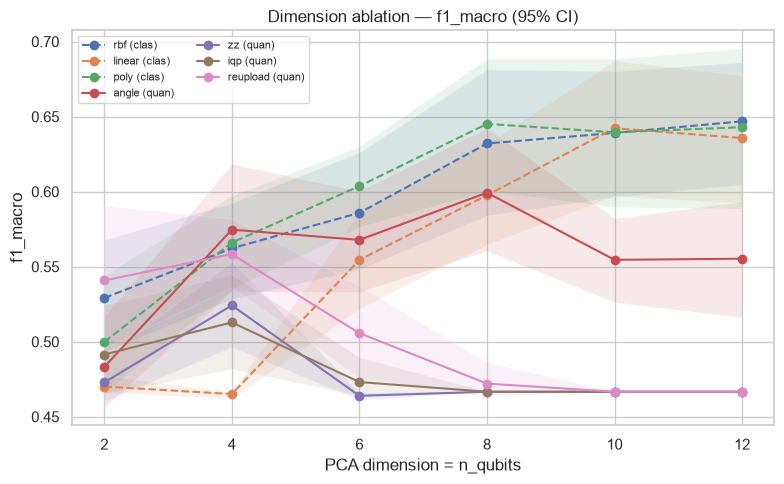

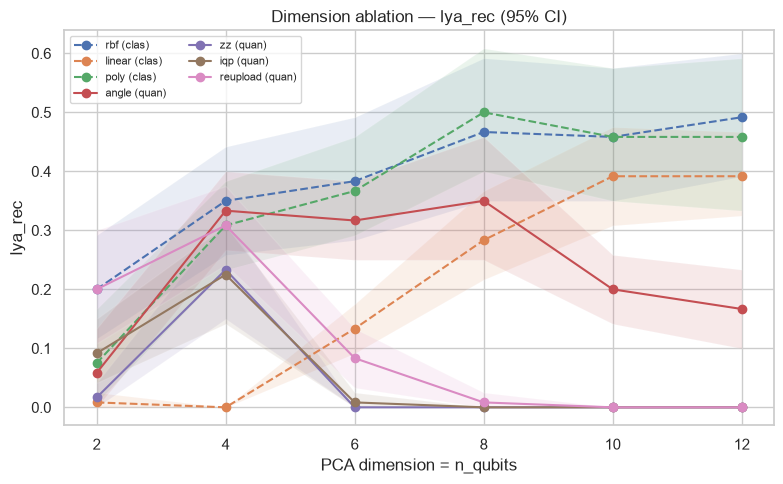

In [15]:
def sweep_curve(results, family_key, metric):
    """family_key = ('rbf', 'classical') or ('iqp','quantum'). Returns dims, mean, lo, hi."""
    name, fam = family_key
    dims, mean, lo, hi = [], [], [], []
    for d in results["pca_dims"]:
        s = summarize(results[fam][(name, d)])[metric]
        dims.append(d); mean.append(s["mean"]); lo.append(s["lo"]); hi.append(s["hi"])
    return np.array(dims), np.array(mean), np.array(lo), np.array(hi)

def plot_pca_sweep(results, metric="f1_macro"):
    fig, ax = plt.subplots(figsize=(8, 5))
    curves = [("rbf", "classical"), ("linear", "classical"), ("poly", "classical")]
    curves += [(m, "quantum") for m in results_feature_maps(results)]
    for name, fam in curves:
        d, m, lo, hi = sweep_curve(results, (name, fam), metric)
        ls = "--" if fam == "classical" else "-"
        ax.plot(d, m, ls, marker="o", label=f"{name} ({fam[:4]})")
        ax.fill_between(d, lo, hi, alpha=0.12)
    ax.set_xlabel("PCA dimension = n_qubits"); ax.set_ylabel(metric)
    ax.set_title(f"Dimension ablation — {metric} (95% CI)")
    ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

plot_pca_sweep(results, "f1_macro")
plot_pca_sweep(results, "lya_rec")

## 12 · Ablation — kernel geometry (before classification)

Diagnostics table: KTA, rank, condition number, `identity_gap` for each kernel at `DIM_REF`.
A quantum KTA > KTA(RBF) is a *necessary* (not sufficient) condition to hope for an advantage.

In [16]:
def diagnostics_table(results, dim):
    rows = []
    for kind in ["linear", "rbf", "poly"]:
        s = summarize(results["classical"][(kind, dim)])
        rows.append(dict(kernel=f"{kind} (classical)", kta=fmt(s["kta"]),
                         rank=f"{s['rank']['mean']:.0f}", cond=f"{s['cond']['mean']:.1e}",
                         identity_gap=fmt(s["identity_gap"])))
    for fmap in results_feature_maps(results):
        s = summarize(results["quantum"][(fmap, dim)])
        rows.append(dict(kernel=f"{fmap} (quantum)", kta=fmt(s["kta"]),
                         rank=f"{s['rank']['mean']:.0f}", cond=f"{s['cond']['mean']:.1e}",
                         identity_gap=fmt(s["identity_gap"])))
    return pd.DataFrame(rows)

print(f"── Kernel diagnostics @ PCA={DIM_REF} ──")
display(diagnostics_table(results, DIM_REF))

── Kernel diagnostics @ PCA=8 ──


,kernel,kta,rank,cond,identity_gap
0,linear (classical),"0.046 [0.040, 0.053]",47,1.9e+10,"4.877 [4.851, 4.896]"
1,rbf (classical),"0.065 [0.060, 0.069]",88,1.3e+04,"0.749 [0.746, 0.752]"
2,poly (classical),"0.056 [0.049, 0.065]",88,2.1e+05,"-0.646 [-0.661, -0.629]"
3,angle (quantum),"0.086 [0.082, 0.090]",88,2.1e+02,"0.953 [0.950, 0.957]"
4,zz (quantum),"0.080 [0.080, 0.081]",88,1.8e+00,"0.996 [0.996, 0.996]"
5,iqp (quantum),"0.080 [0.079, 0.081]",88,3.6e+00,"0.982 [0.981, 0.984]"
6,reupload (quantum),"0.084 [0.083, 0.085]",88,8.1e+00,"0.990 [0.989, 0.991]"


## 13 · Ablation — imbalance strategy

Comparison of `class_weight="balanced"` vs controlled undersampling of LYT (~3:1 ratio),
on the best quantum feature map and on RBF. Change `CFG.IMBALANCE` and rerun
`run_full_sweep(..., force=True)` into a second cache, then compare LYA recall/precision.

In [17]:
def compare_imbalance(res_balanced, res_undersample, family_key, dim):
    name, fam = family_key
    out = {}
    for tag, res in [("balanced", res_balanced), ("undersample", res_undersample)]:
        s = summarize(res[fam][(name, dim)])
        out[tag] = dict(lya_recall=fmt(s["lya_rec"]), lya_prec=fmt(s["lya_prec"]),
                        f1=fmt(s["f1_macro"]), bacc=fmt(s["bacc"]))
    return pd.DataFrame(out).T

# Usage example:
CFG.IMBALANCE = "undersample"
results_us = run_full_sweep(X, y, CFG, force=True)   # write to another RES_CACHE if needed
CFG.IMBALANCE = "balanced"
display(compare_imbalance(results, results_us, ("iqp","quantum"), DIM_REF))

  PCA= 2 qubits ✓  (95s)
  PCA= 4 qubits ✓  (207s)
  PCA= 6 qubits ✓  (244s)
  PCA= 8 qubits ✓  (282s)
  PCA=10 qubits ✓  (333s)
  PCA=12 qubits ✓  (424s)
Sweep finished & cached.


,lya_recall,lya_prec,f1,bacc
balanced,"0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.467 [0.467, 0.467]","0.500 [0.500, 0.500]"
undersample,"0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.467 [0.467, 0.467]","0.500 [0.500, 0.500]"


## 14 · Summary visualizations

- **F1 / LYA-recall** bars with 95% CI (classical vs quantum) at `DIM_REF`.
- **KTA** comparison, quantum vs classical.
- Aggregated confusion matrix for the best quantum kernel.
- 2D PCA projection colored by class (separability context).

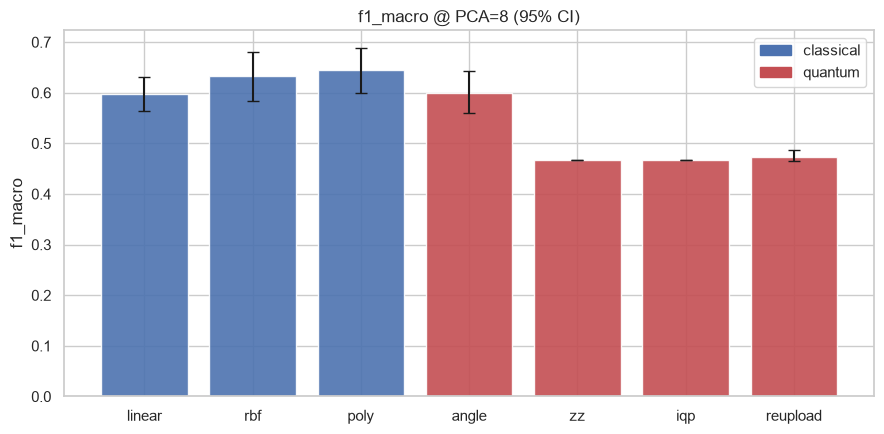

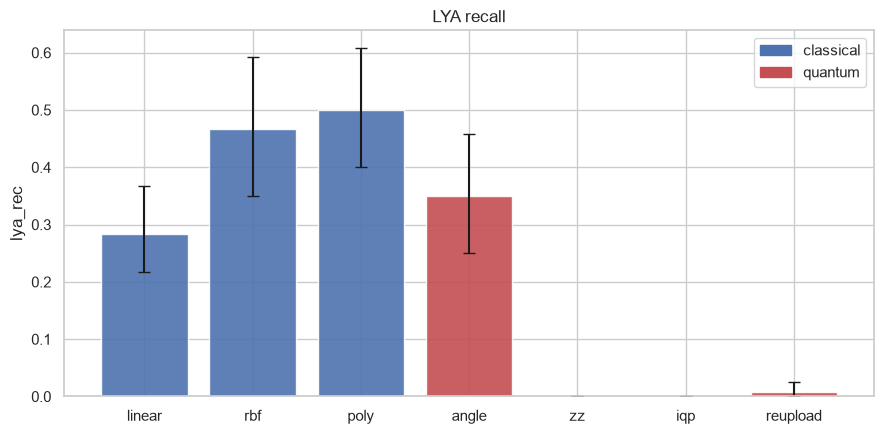

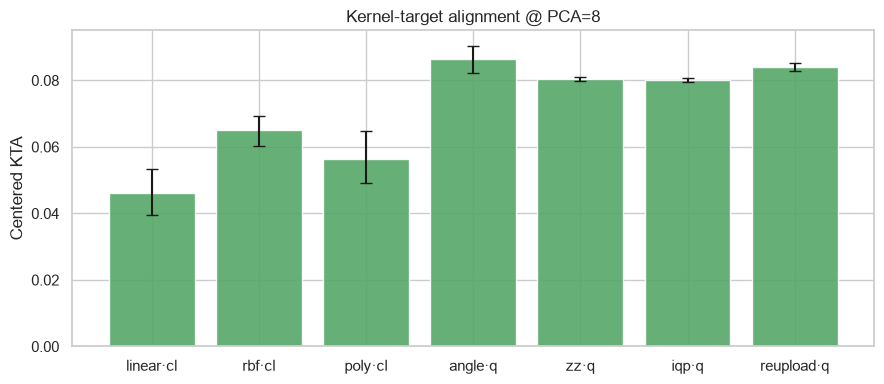

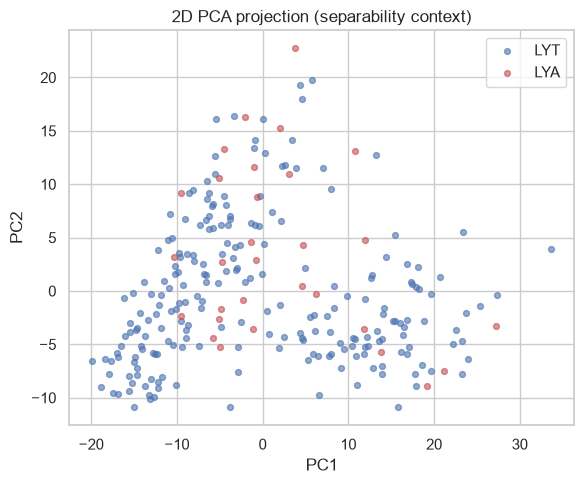

In [18]:
def plot_summary_bars(results, dim, metric="f1_macro", title=None):
    names, means, los, his, fams = [], [], [], [], []
    for kind in ["linear", "rbf", "poly"]:
        s = summarize(results["classical"][(kind, dim)])[metric]
        names.append(kind); means.append(s["mean"]); los.append(s["lo"]); his.append(s["hi"]); fams.append("classical")
    for fmap in results_feature_maps(results):
        s = summarize(results["quantum"][(fmap, dim)])[metric]
        names.append(fmap); means.append(s["mean"]); los.append(s["lo"]); his.append(s["hi"]); fams.append("quantum")
    colors = ["#4C72B0" if f == "classical" else "#C44E52" for f in fams]
    err = np.array([np.array(means) - np.array(los), np.array(his) - np.array(means)])
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(names, means, yerr=err, color=colors, capsize=4, alpha=0.9)
    ax.set_ylabel(metric); ax.set_title(title or f"{metric} @ PCA={dim} (95% CI)")
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color="#4C72B0", label="classical"),
                       Patch(color="#C44E52", label="quantum")])
    plt.tight_layout(); plt.show()

def plot_kta_compare(results, dim):
    labels, ktas, err = [], [], [[], []]
    for kind in ["linear", "rbf", "poly"]:
        s = summarize(results["classical"][(kind, dim)])["kta"]
        labels.append(f"{kind}·cl"); ktas.append(s["mean"])
        err[0].append(s["mean"]-s["lo"]); err[1].append(s["hi"]-s["mean"])
    for fmap in results_feature_maps(results):
        s = summarize(results["quantum"][(fmap, dim)])["kta"]
        labels.append(f"{fmap}·q"); ktas.append(s["mean"])
        err[0].append(s["mean"]-s["lo"]); err[1].append(s["hi"]-s["mean"])
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(labels, ktas, yerr=np.array(err), capsize=4, color="#55A868", alpha=0.9)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_ylabel("Centered KTA"); ax.set_title(f"Kernel-target alignment @ PCA={dim}")
    plt.tight_layout(); plt.show()

def plot_pca_scatter(X, y, seed=SEED):
    sc = StandardScaler().fit_transform(X)
    Z = PCA(n_components=2, random_state=0).fit_transform(sc)
    fig, ax = plt.subplots(figsize=(6, 5))
    for cls, name, c in [(0, "LYT", "#4C72B0"), (1, "LYA", "#C44E52")]:
        m = (y == cls)
        ax.scatter(Z[m, 0], Z[m, 1], s=18, alpha=0.6, label=name, color=c)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.set_title("2D PCA projection (separability context)"); ax.legend()
    plt.tight_layout(); plt.show()

plot_summary_bars(results, DIM_REF, "f1_macro")
plot_summary_bars(results, DIM_REF, "lya_rec", title="LYA recall")
plot_kta_compare(results, DIM_REF)
plot_pca_scatter(X, y)

## 15 · Automatic verdict (central question)

Sweeps all dimensions and feature maps; records cases where a quantum kernel **beats RBF with a CI excluding 0** on F1, LYA recall, or PR-AUC. Honest summary: real advantage, tie within noise, or inferiority.

In [19]:
def verdict(results, keys=("f1_macro", "lya_rec", "pr_auc")):
    wins, ties, losses = [], [], []
    for d in results["pca_dims"]:
        rbf = results["classical"][("rbf", d)]
        for fmap in results_feature_maps(results):
            q = results["quantum"][(fmap, d)]
            for k in keys:
                dd = paired_delta(q, rbf, k)
                tag = (fmap, d, k, round(dd["mean"], 3), round(dd["lo"], 3), round(dd["hi"], 3))
                if dd["significant"] and dd["mean"] > 0:   wins.append(tag)
                elif dd["significant"] and dd["mean"] < 0: losses.append(tag)
                else:                                      ties.append(tag)
    print(f"Paired comparisons quantum vs RBF: {len(wins)+len(ties)+len(losses)}")
    print(f"  ▸ quantum advantage (CI excludes 0, Δ>0): {len(wins)}")
    print(f"  ▸ indistinguishable (CI contains 0)      : {len(ties)}")
    print(f"  ▸ RBF superior (CI excludes 0, Δ<0)      : {len(losses)}")
    if wins:
        print("\nCases of quantum advantage (map, dim, metric, Δ [lo,hi]):")
        for w in wins: print("   ", w)
    else:
        print("\nNo statistically supported quantum advantage on this dataset — "
              "an honest, publishable result (diagnosing 'when quantum doesn't help').")
    return dict(wins=wins, ties=ties, losses=losses)

verdict(results)

Paired comparisons quantum vs RBF: 72
  ▸ quantum advantage (CI excludes 0, Δ>0): 0
  ▸ indistinguishable (CI contains 0)      : 15
  ▸ RBF superior (CI excludes 0, Δ<0)      : 57

No statistically supported quantum advantage on this dataset — an honest, publishable result (diagnosing 'when quantum doesn't help').


{'wins': [],
 'ties': [('zz', 2, 'pr_auc', -0.051, -0.105, 0.009),
  ('reupload', 2, 'f1_macro', 0.012, -0.038, 0.062),
  ('reupload', 2, 'lya_rec', 0.0, -0.125, 0.117),
  ('reupload', 2, 'pr_auc', -0.01, -0.068, 0.041),
  ('angle', 4, 'f1_macro', 0.012, -0.016, 0.045),
  ('angle', 4, 'lya_rec', -0.017, -0.108, 0.083),
  ('angle', 4, 'pr_auc', -0.015, -0.059, 0.031),
  ('zz', 4, 'f1_macro', -0.038, -0.084, 0.013),
  ('zz', 4, 'lya_rec', -0.117, -0.25, 0.017),
  ('iqp', 4, 'lya_rec', -0.125, -0.258, 0.017),
  ('reupload', 4, 'f1_macro', -0.004, -0.035, 0.03),
  ('reupload', 4, 'lya_rec', -0.042, -0.133, 0.042),
  ('angle', 6, 'f1_macro', -0.018, -0.051, 0.015),
  ('angle', 6, 'lya_rec', -0.067, -0.175, 0.025),
  ('angle', 8, 'f1_macro', -0.033, -0.082, 0.016)],
 'losses': [('angle', 2, 'f1_macro', -0.046, -0.075, -0.022),
  ('angle', 2, 'lya_rec', -0.142, -0.233, -0.067),
  ('angle', 2, 'pr_auc', -0.064, -0.115, -0.024),
  ('zz', 2, 'f1_macro', -0.056, -0.099, -0.015),
  ('zz', 2, 'lya_